In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

using: /kaggle/input/datasets/dfydata/the-online-plain-text-english-dictionary-opted/OPTED-Dictionary.csv (16.6 MB)
other csvs found: ['test_ids.csv']
column map -> word='Word'  definition='Definition'  pos='POS'  count='Count'  (all: ['Word', 'Count', 'POS', 'Definition'])
sanity check: median definition length = 46 chars  -> looks like real text.
sample rows:
  word Count POS                                                                     definition pos count
0    A     1  ""  The first letter of the English and of many other alphabets. The capital A...  ""     1
1    A     1  ""  The name of the sixth tone in the model major scale (that in C)  or the fi...  ""     1
2    A     1  ""  An adjective  commonly called the indefinite article and signifying one or...  ""     1
3    A     1  ""  In each; to or for each; as  """"twenty leagues a day"""" """"a hundred po...  ""     1

1. SHAPE / INTEGRITY
  rows                                                 176,004
  distinct target wor

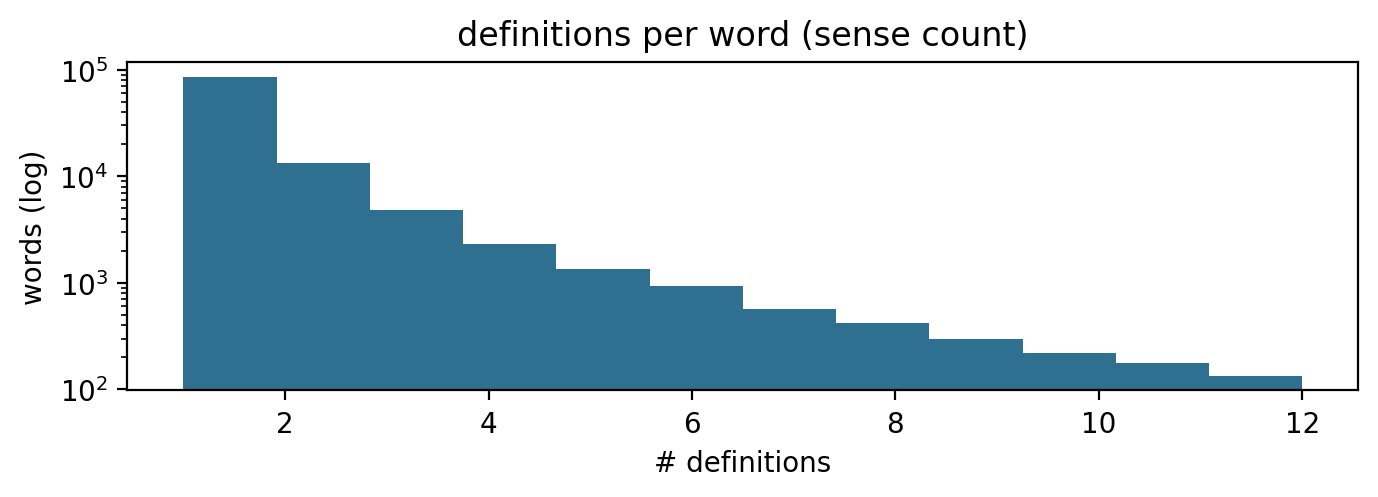

  -> IMPLICATION: target is many-to-many. Accuracy/F1 are ill-posed here;
     the rubric's Recall@1/10/100 + Median Rank is the *correct* metric, by reason.

3. DEFINITION COLLISIONS  (one description, many valid words)
  rows whose definition maps to >1 distinct word       18,321 (10.41%)
  max words tied to a single definition string         9
  APPROX CEILING on Recall@1 (oracle ranks the tie-set first) 0.944
  definitions with >1 word                             8,459 (100.00%)
  worst tie: 'the pintail duck.'  -> 2 words
  -> IMPLICATION: if the ceiling is well below 1.0, a Recall@1 of e.g. 0.86 is not
     '86% correct'. Report STRICT and SENSE-TOLERANT Recall@k (hit if ANY word sharing
     that definition is returned). Also worth noting near-duplicate (not verbatim)
     definitions will push the true ceiling lower still; say that as a limitation.

4. LABEL LEAKAGE  (definition contains its own target word)
  rows where the definition repeats the target word    23,940 (13.60%)

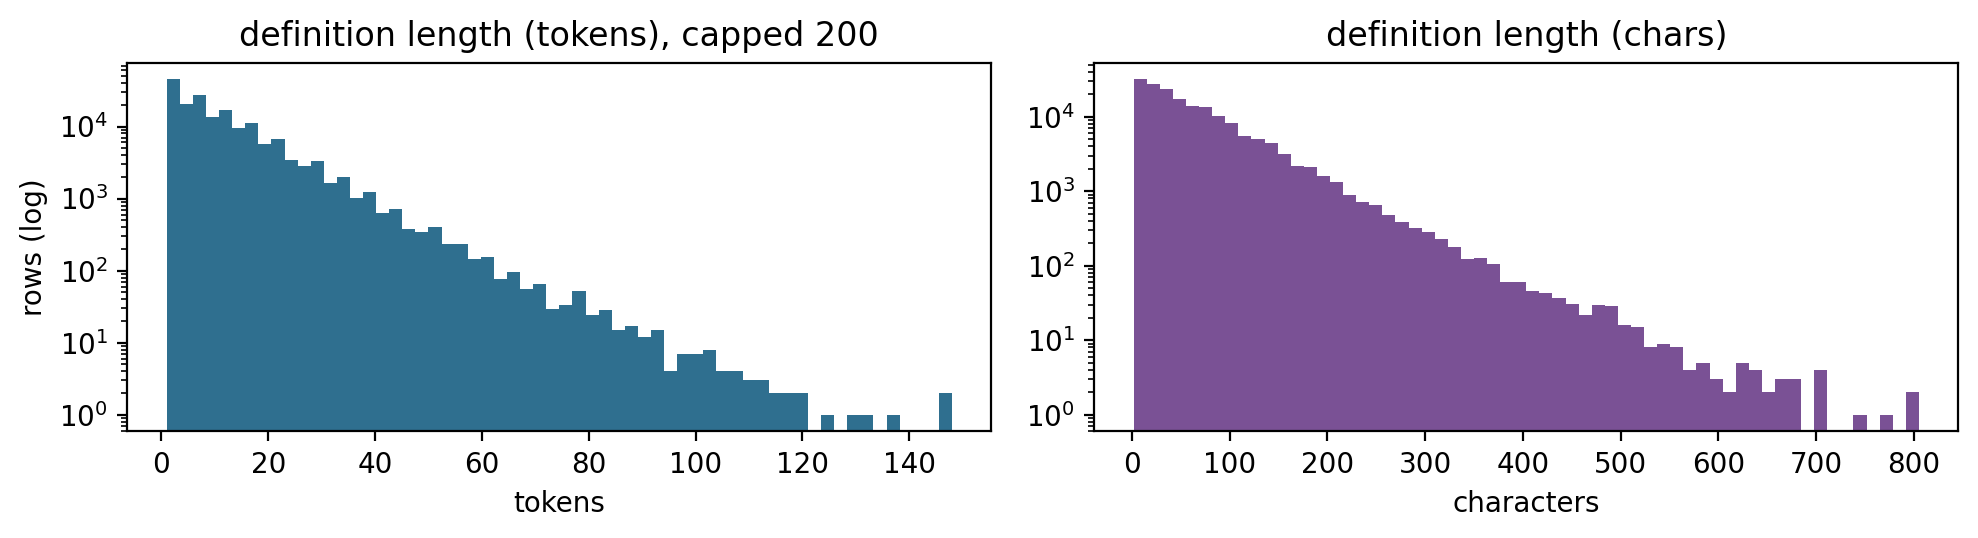

  truncation loss by max_seq_length:
      max_len= 16  rows losing >0 tokens:  38,797  (22.04%)
      max_len= 32  rows losing >0 tokens:   8,050  ( 4.57%)
      max_len= 48  rows losing >0 tokens:   1,911  ( 1.09%)
      max_len= 64  rows losing >0 tokens:     495  ( 0.28%)
      max_len= 96  rows losing >0 tokens:      48  ( 0.03%)
      max_len=128  rows losing >0 tokens:       5  ( 0.00%)
      max_len=256  rows losing >0 tokens:       0  ( 0.00%)
  -> PICK max_seq_length = 32 (<= 4.57% of rows truncated). Quote this in the report.

7. NON-LEARNING BASELINES (honesty check)
  uniform random guess over dictionary -> Recall@1     8.96e-06
  always-answer most-frequent word -> Recall@1         0.001170   ('#name?')
  always-answer from top-50 most frequent words -> Recall@1 0.0111
  -> If a trained model beats BM25 but not the frequency prior, it learned nothing.
     Report these two rows next to your model numbers.

8. EVAL PROTOCOL
  a) split by WORD, not by row (a word's other se

In [2]:
#EDA OF OPTED DATASET

import glob, re, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

# ---------------------------------------------------------------- 0. find the data
cands = glob.glob('/kaggle/input/**/*.csv', recursive=True) + glob.glob('**/*.csv', recursive=True)
def score(p):                                   # prefer OPTED-ish, then biggest file
    s = os.path.basename(p).lower()
    return (any(k in s for k in ('opted', 'dict')), os.path.getsize(p))
cands = sorted(set(cands), key=score, reverse=True)
assert cands, "No CSV found under /kaggle/input - Attach a Kaggle Dataset (search: OPTED) first."
PATH = cands[0]
print("using:", PATH, f"({os.path.getsize(PATH)/1e6:.1f} MB)")
if len(cands) > 1:
    print("other csvs found:", [os.path.basename(c) for c in cands[1:5]])

# >>> if this block ever picks the wrong column, set these two by hand and re-run
FORCE = {"word": None, "definition": None, "pos": None}

df = pd.read_csv(PATH, dtype=str).fillna("")
cols = list(df.columns); lc = {c.lower(): c for c in cols}

def _find(*pats):
    for p in pats:
        for c in cols:
            if re.search(p, c.lower()): return c
    return None

WC = FORCE["word"]       or _find(r"^word$", r"word", r"term", r"entry", r"headword") or cols[0]
DC = FORCE["definition"] or _find(r"defin", r"gloss", r"meaning", r"senses?", r"expl")
PC = FORCE["pos"]        or _find(r"^pos$", r"part.of.speech", r"pos")
CC = _find(r"^count$", r"freq")
assert DC and DC != WC, f"Could not find a definition column among {cols}. Set FORCE['definition'] by hand."
print(f"column map -> word={WC!r}  definition={DC!r}  pos={PC!r}  count={CC!r}  (all: {cols})")
df = df.rename(columns={WC: "word", DC: "definition"})
if PC: df["pos"] = df[PC].astype(str)
if CC: df["count"] = CC and df[CC].astype(str)
for col in ("word", "definition"):
    s = df[col].astype(str).str.strip().str.strip('"').str.strip()
    df[col] = s
df = df[(df["definition"].str.len() > 1)]

_m = df["definition"].str.len().median()
if _m < 12:
    print(f"\n*** SANITY WARNING: median 'definition' length is only {_m:.0f} chars."
          f"\n*** Column detection is probably wrong. Available columns: {cols}"
          f"\n*** Set FORCE['definition'] = '<the right one>' at the top and re-run. ***\n")
else:
    print(f"sanity check: median definition length = {_m:.0f} chars  -> looks like real text.")

toks = lambda s: [t for t in re.split(r"[^A-Za-z']+", str(s)) if t]

def section(t): print("\n" + "="*72 + f"\n{t}\n" + "="*72)
def line(k, v): print(f"  {k:<52} {v}")
def pct(n, d): return f"{n:,} ({100.0*n/max(1,d):.2f}%)"

print("sample rows:")
print(df.head(4).to_string(max_colwidth=78))

# ---------------------------------------------------------------- 1. shape
section("1. SHAPE / INTEGRITY")
n = len(df); uw = df["word"].nunique(); ud = df["definition"].nunique()
line("rows", f"{n:,}")
line("distinct target words (dictionary size)", f"{uw:,}")
line("distinct definition strings", f"{ud:,}")
line("empty definitions", pct((df['definition']=='').sum(), n))
line("exact duplicate (word,definition) rows", pct(df.duplicated().sum(), n))
line("rows per word (senses per entry)", f"{n/max(1,uw):.3f}")

# ---------------------------------------------------------------- 2. POLYSEMY  <- the guide's 'bank'
section("2. POLYSEMY  (one word, many senses)")
per_word = df.groupby("word").size()
line("words with >1 definition", pct((per_word > 1).sum(), uw))
line("mean definitions per word", f"{per_word.mean():.3f}")
line("max definitions on one word", f"{per_word.max()}")
print("  most polysemous words ->")
for w, k in per_word.sort_values(ascending=False).head(12).items():
    print(f"      {w!r:<22} {k} senses")
plt.figure(figsize=(7, 2.6))
plt.hist(per_word[per_word <= 12], bins=12, color="#2f6f8f")
plt.title("definitions per word (sense count)"); plt.xlabel("# definitions"); plt.ylabel("words (log)")
plt.yscale("log"); plt.tight_layout(); plt.show()
print("  -> IMPLICATION: target is many-to-many. Accuracy/F1 are ill-posed here;")
print("     the rubric's Recall@1/10/100 + Median Rank is the *correct* metric, by reason.")

# ---------------------------------------------------------------- 3. SYNONYMY -> ceiling on Recall@1
section("3. DEFINITION COLLISIONS  (one description, many valid words)")
t = df["definition"].str.lower().str.strip()
words_per_def = df.assign(_td=t).groupby("_td")["word"].nunique()   # distinct WORDS per definition
k = t.map(words_per_def)                                            # k for each row
df["_k"] = k
shared_rows = int((k > 1).sum())
line("rows whose definition maps to >1 distinct word", pct(shared_rows, len(df)))
line("max words tied to a single definition string", f"{int(words_per_def.max())}")
tie_defs = words_per_def[words_per_def > 1]
ceil_est = float((1.0 / k).mean())
line("APPROX CEILING on Recall@1 (oracle ranks the tie-set first)", f"{ceil_est:.3f}")
line("definitions with >1 word", pct(len(tie_defs), df["_td"].nunique() if "_td" in df else len(tie_defs)))
if len(tie_defs):
    ex = tie_defs.sort_values(ascending=False).index[0]
    print(f"  worst tie: {ex[:86]!r}  -> {int(tie_defs.iloc[0])} words")
print("  -> IMPLICATION: if the ceiling is well below 1.0, a Recall@1 of e.g. 0.86 is not")
print("     '86% correct'. Report STRICT and SENSE-TOLERANT Recall@k (hit if ANY word sharing")
print("     that definition is returned). Also worth noting near-duplicate (not verbatim)")
print("     definitions will push the true ceiling lower still; say that as a limitation.")

# ---------------------------------------------------------------- 4. LEAKAGE
section("4. LABEL LEAKAGE  (definition contains its own target word)")
leak = np.array([bool(re.search(r"\b" + re.escape(str(w).lower()) + r"\b", str(d).lower()))
                 if str(w).strip() else False for w, d in zip(df["word"], df["definition"])])
line("rows where the definition repeats the target word", pct(int(leak.sum()), n))
for i in np.where(leak)[0][:4]:
    print(f"      {df['word'].iloc[i]!r}: {df['definition'].iloc[i][:80]!r}")
wlen = df["word"].str.len()
long_mask = wlen >= 3
line("  restricted to headwords of length >=3 (removes 1-2 char false matches)",
     pct(int(leak[long_mask].sum()), int(long_mask.sum())))
print(f"  NOTE: single/double-letter headwords (a, I, be, to, of) match almost any text via"
      f"\\b-word-matching, which inflates the figure above ({100.0*leak[~long_mask].mean() if (~long_mask).any() else 0:.1f}% of them 'leak')."
      f"\n        Quote the length>=3 number as your leakage estimate, and mention you gated it.")
print("  -> IMPLICATION: retrievers can win by lexical copy. This inflates BM25 MOST,")
print("     i.e. it SHRINKS your dense-vs-lexical gain. Report the leakage-free subset too.")

# ---------------------------------------------------------------- 5. NOISE
section("5. NOISE INVENTORY")
d = df["definition"]
checks = {
  "definition <3 tokens":            d.map(lambda x: len(toks(x)) < 3),
  "definition >250 chars":           d.str.len() > 250,
  "cross-reference only (see/same)": d.str.match(r"^\s*(see|same as|another spelling)\b", case=False),
  "parenthetical domain tag (..)":   d.str.contains(r"\([^)]{2,30}\)", regex=True),
  "contains digits":                 d.str.contains(r"\d", regex=True),
  "non-Latin chars (off-scope)":     d.str.contains(r"[^\x00-\x7F]", regex=True),
  "' OR ' multi-sense in one row":   d.str.contains(r"\s+OR\s+", regex=True),
  "multi-word target entry":         df["word"].str.contains(" ", regex=False),
  "target has non-alpha chars":      df["word"].str.contains(r"[^A-Za-z\-']", regex=True),
  "spreadsheet error tokens in WORD": df["word"].str.contains(r"#NAME|#REF|#VALUE|#DIV|\?\?\?", case=False, regex=True),
  "definition still quote-wrapped":   d.str.startswith('"'),
  "quadruple-quote artefacts":        d.str.contains('""""', regex=False),
  "no terminal punctuation":         ~d.str.contains(r"[.!?;:]\s*$", regex=True),
}
for k, m in checks.items():
    print(f"  {int(m.sum()):>7,}  ({100.0*int(m.sum())/max(1,n):5.2f}%)  {k}")
    if int(m.sum()) and ("cross-reference" in k or "OR" in k or "non-Latin" in k):
        print(f"        e.g. {d[m].iloc[0][:76]!r}")
if "pos" in df:
    nz = df["pos"].astype(str).str.strip().str.strip('"')
    ok = nz[(nz != "") & (nz.str.lower() != "nan") & nz.str.match(r"^[a-z]$")]
    print(f"\n  POS column: {(len(ok)/len(df)*100):.2f}% of rows carry a usable POS tag")
    if len(ok):
        print("     value counts:", ok.value_counts().head(8).to_dict())
        print("     -> If POS is populated it is exactly the signal Zhang et al. 2020 (multi-channel RD,")
        print("        cited IN YOUR BRIEF) uses as an auxiliary head to disambiguate 'bank'. Worth proposing.")
    else:
        print("     -> POS present but empty. Say so: the multi-channel approach then needs tags added (e.g. UD).")
if "count" in df:
    print("  'Count' column detected: use it for a *sense-frequency* prior baseline, not just a word prior.")
print("  -> He scoped this to English: state the single rule you applied for removal, and")
print("     how many rows it drops. Do NOT hand-wave 'we cleaned it'.")

# ---------------------------------------------------------------- 6. LENGTH -> max_seq_length
section("6. DEFINITION LENGTH  (why the histogram exists)")
tl = d.map(lambda x: len(toks(x))); cl = d.str.len()
line("token length p50 / p90 / p95 / p99 / max",
     f"{tl.quantile(.5):.0f} / {tl.quantile(.9):.0f} / {tl.quantile(.95):.0f} / {tl.quantile(.99):.0f} / {tl.max():.0f}")
line("char length p50 / p95 / max", f"{cl.quantile(.5):.0f} / {cl.quantile(.95):.0f} / {cl.max():.0f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
ax[0].hist(tl[tl <= 200], bins=60, color="#2f6f8f"); ax[0].set_title("definition length (tokens), capped 200")
ax[0].set_xlabel("tokens"); ax[0].set_ylabel("rows (log)"); ax[0].set_yscale("log")
ax[1].hist(cl[cl <= 1200], bins=60, color="#7a5195"); ax[1].set_title("definition length (chars)")
ax[1].set_xlabel("characters"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()
print("  truncation loss by max_seq_length:")
table = []
for L in (16, 32, 48, 64, 96, 128, 256):
    aff = int((tl > L).sum()); table.append((L, aff, 100.0*aff/max(1, n)))
    print(f"      max_len={L:>3}  rows losing >0 tokens: {aff:>7,}  ({100.0*aff/max(1,n):5.2f}%)")
knee = min([r for r in table if r[2] <= 5.0], key=lambda r: r[0], default=table[-1])
print(f"  -> PICK max_seq_length = {knee[0]} (<= {knee[2]:.2f}% of rows truncated). Quote this in the report.")
df["_tl"] = tl

# ---------------------------------------------------------------- 7. baselines you must report
section("7. NON-LEARNING BASELINES (honesty check)")
prior = df["word"].str.lower().value_counts()
line("uniform random guess over dictionary -> Recall@1", f"{1.0/max(1,uw):.2e}")
line("always-answer most-frequent word -> Recall@1", f"{prior.iloc[0]/n:.6f}   ({prior.index[0]!r})")
line("always-answer from top-50 most frequent words -> Recall@1", f"{prior.head(50).sum()/n:.4f}")
print("  -> If a trained model beats BM25 but not the frequency prior, it learned nothing.")
print("     Report these two rows next to your model numbers.")

# ---------------------------------------------------------------- 8. protocol + holdout
section("8. EVAL PROTOCOL")
print("  a) split by WORD, not by row (a word's other senses must not sit in the candidate pool)")
print("  b) at query time REMOVE the exact gold row from the pool, else Recall@1 -> ~1.0")
print("  c) n_test = 500 per rubric, fixed seed, save the ids so it reproduces")
rng = np.random.default_rng(0)
test_idx = rng.choice(n, size=min(500, n), replace=False)
np.savetxt("test_ids.csv", test_idx, fmt="%d", delimiter=",")
try:
    with open("/kaggle/working/test_ids.csv", "w") as f:      # lands in the notebook output
        f.write(",".join(str(int(i)) for i in test_idx))
    print(f"  wrote {len(test_idx)} held-out ids -> /kaggle/working/test_ids.csv")
except Exception as e:
    print("  (could not write to /kaggle/working:", e, ")")
print("  d) Median Rank: state the undefined-rank capping convention you use (WantWords caps at 1000)")

# ---------------------------------------------------------------- POINTS IDENTIFIED
section("POINTS IDENTIFIED  <- screenshot this block; it IS the deliverable he asked for")
rows = [
 ("dictionary size / rows", f"{uw:,} words over {n:,} rows"),
 ("sense ambiguity (polysemy)", f"{100.0*(per_word>1).sum()/max(1,uw):.2f}% of words carry >1 definition -> model-side difficulty, and why Recall@k not accuracy"),
 ("definition collisions (synonymy)", f"{100.0*shared_rows/max(1,n):.2f}% of rows map to >1 distinct word; approx Recall@1 ceiling {min(1.0, ceil_est):.3f}"),
 ("label leakage", f"{100.0*leak.mean():.2f}% of definitions name their own target -> report leakage-free subset separately"),
 ("noise", f"<3-token defs {100.0*checks['definition <3 tokens'].mean():.2f}%, cross-refs {100.0*checks['cross-reference only (see/same)'].mean():.2f}%, non-Latin {100.0*checks['non-Latin chars (off-scope)'].mean():.2f}% -> cleaning rules in CLEANING.md"),
 ("length / truncation", f"p95={tl.quantile(.95):.0f} tokens; max_seq_length={knee[0]} keeps truncation to {knee[2]:.2f}% of rows"),
 ("baselines", f"random {1.0/max(1,uw):.1e}; unigram prior {prior.head(50).sum()/n:.4f} -> any model must clear these"),
 ("protocol", "word-level split, gold row removed from pool, 500-query seed-fixed holdout, Median Rank capping stated"),
]
for k, v in rows:
    print(f"  * {k}: {v}")
print("\n  -> DESIGN DECISIONS THIS FORCES (say these out loud in the meeting):")
print("     1. report strict + sense-tolerant Recall@k, with the collision ceiling quoted beside them")
print("     2. dual metrics on all rows vs leakage-free rows")
print("     3. max_seq_length set from the truncation table, not guessed")
print("     4. frequency-prior baseline included so the dense-vs-lexical gap is believable")
